# Diabetic Retinopathy using GoogLeNet

## 1. Import Library

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, AveragePooling2D, Flatten, Dense, Dropout, concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
import pickle
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

I0000 00:00:1785429767.753710   42405 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1785429770.311154   42405 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [ ]:
# Xóa rác bộ nhớ GPU
tf.keras.backend.clear_session()

## 2. Load Data

In [ ]:
BATCH_SIZE=4

In [ ]:
with open("../../../data/processed/aptos/sample_100/sample_dataset.pkl", "rb") as f: #[cite: 1]
    data = pickle.load(f)

In [ ]:
with open("../../../data/processed/aptos/test_images/sample_dataset.pkl", "rb") as f:
    data_test = pickle.load(f)

## 3. Data Preprocessing 

In [ ]:
X = data['data']
y = data['labels']
class_names = data['class_names']
NUM_CLASSES = len(class_names)
x_train, x_val, y_train, y_val = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)
IMG_SIZE = x_train.shape[1]
print(f'Số mẫu: {len(y_train)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 200 | Số lớp: 5 | Kích thước ảnh: 300x300


In [ ]:
x_test = data_test['data']
y_test = data_test['labels']
print(f'Số mẫu: {len(y_test)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 366 | Số lớp: 5 | Kích thước ảnh: 300x300


In [ ]:
# y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
# y_test  = tf.keras.utils.to_categorical(y_test,  NUM_CLASSES)
# y_val = tf.keras.utils.to_categorical(y_val, NUM_CLASSES)

### Ảnh tệp train

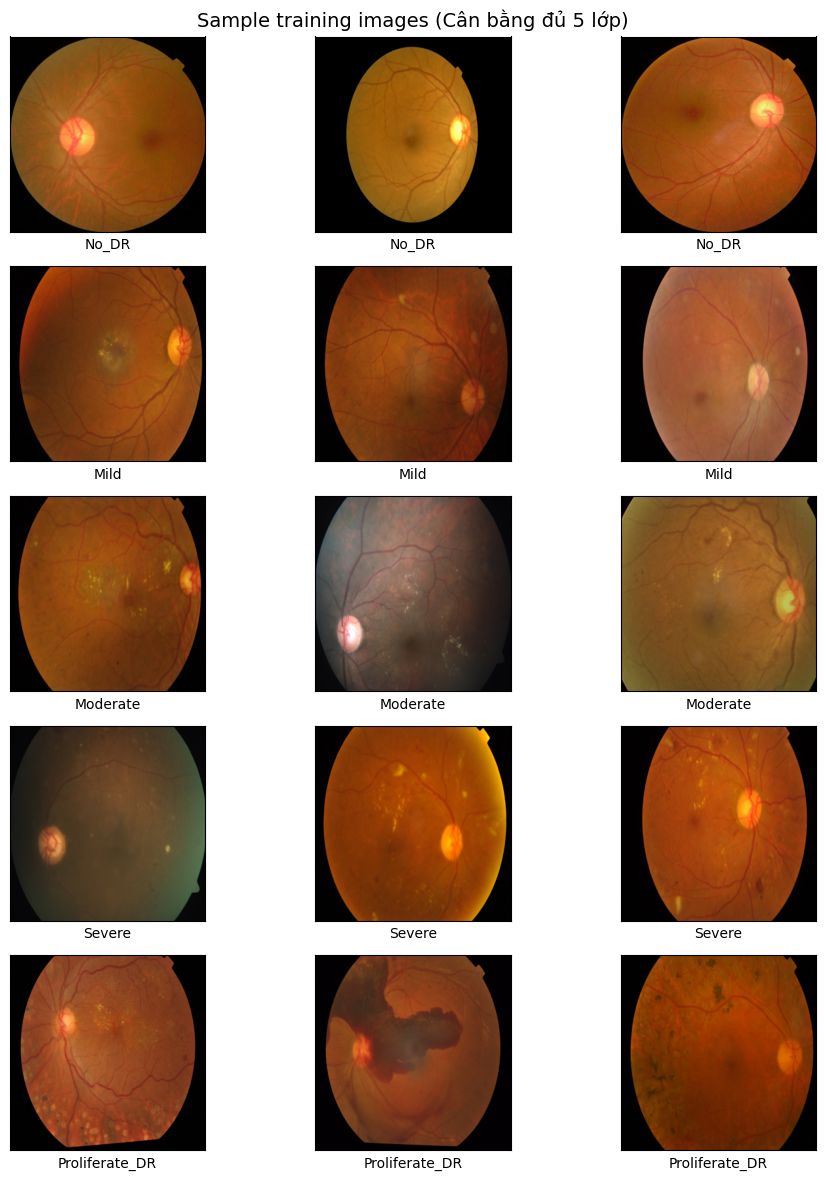

In [ ]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_train, axis=1) if len(y_train.shape) > 1 else y_train

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_train[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample training images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

### Ảnh tệp test

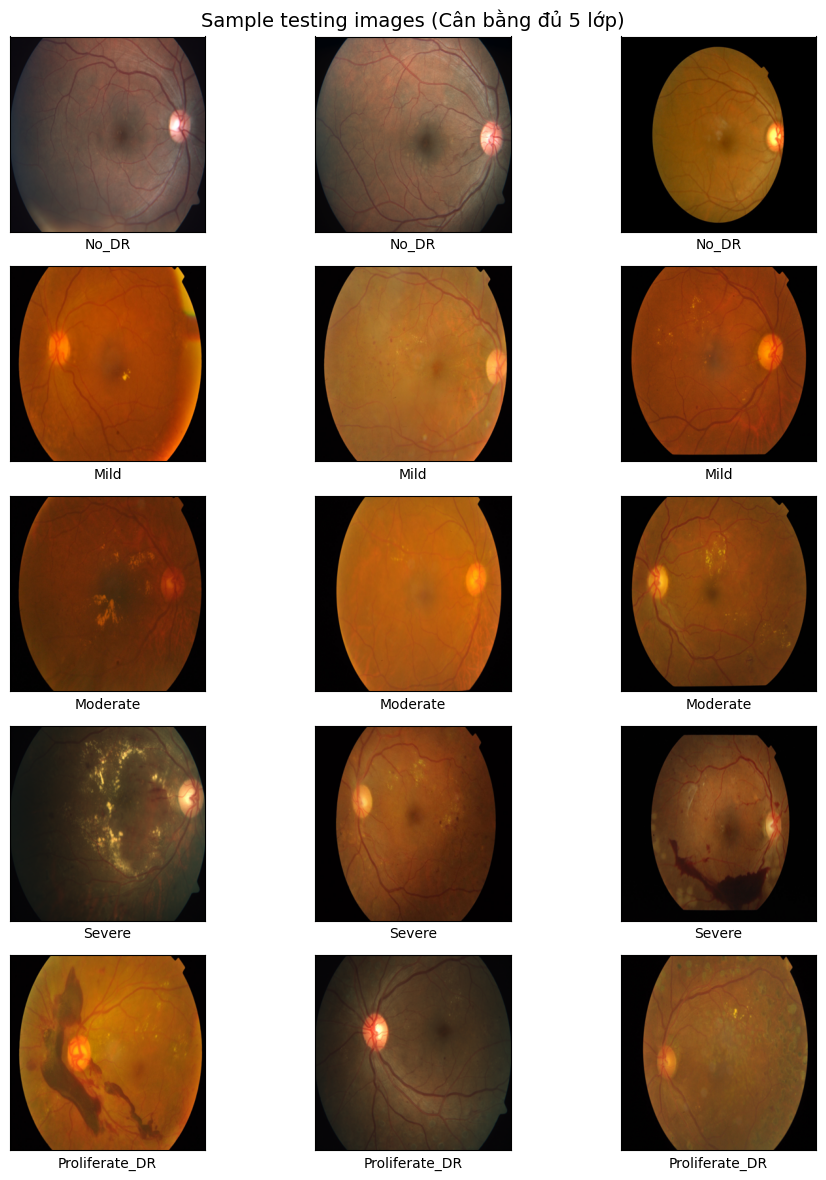

In [ ]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_test[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample testing images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Xây dựng model GoogLeNet

In [ ]:
class BaseConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, **kwargs):
        super(BaseConv2d, self).__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, **kwargs)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.conv(x))

class InceptionModule(nn.Module):
    def __init__(self, in_channels, n1x1, n3x3red, n3x3, n5x5red, n5x5, pool_proj):
        super(InceptionModule, self).__init__()
        self.b1 = nn.Sequential(nn.Conv2d(in_channels, n1x1, kernel_size=1), nn.ReLU(True))
        self.b2 = nn.Sequential(BaseConv2d(in_channels, n3x3red, kernel_size=1), BaseConv2d(n3x3red, n3x3, kernel_size=3, padding=1))
        self.b3 = nn.Sequential(BaseConv2d(in_channels, n5x5red, kernel_size=1), BaseConv2d(n5x5red, n5x5, kernel_size=5, padding=2))
        self.b4 = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1), BaseConv2d(in_channels, pool_proj, kernel_size=1))

    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], 1)

class AuxiliaryClassifier(nn.Module):
    def __init__(self, in_channels, num_classes, dropout=0.7):
        super(AuxiliaryClassifier, self).__init__()
        # SỬA: Dùng AdaptiveAvgPool2d để luôn ra 4x4 (4x4 * 128 channels = 2048) bất chấp size ảnh đầu vào
        self.pool = nn.AdaptiveAvgPool2d((4, 4))
        self.conv = BaseConv2d(in_channels, 128, kernel_size=1)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(2048, 1024)
        self.relu = nn.ReLU(True)
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(1024, num_classes) # SỬA: Truyền num_classes

    def forward(self, x):
        x = self.conv(self.pool(x))
        x = self.fc2(self.dropout(self.relu(self.fc1(self.flatten(x)))))
        return x

class GoogLeNet(nn.Module):
    def __init__(self, num_classes=5, use_aux=True): # SỬA: Thêm tham số num_classes
        super(GoogLeNet, self).__init__()
        self.use_aux = use_aux

        self.conv1 = BaseConv2d(3, 64, kernel_size=7, stride=2, padding=3)
        self.maxpool1 = nn.MaxPool2d(3, stride=2, padding=1)
        self.lrn1 = nn.LocalResponseNorm(5, alpha=0.0001, beta=0.75)

        self.conv2 = BaseConv2d(64, 64, kernel_size=1)
        self.conv3 = BaseConv2d(64, 192, kernel_size=3, padding=1)
        self.lrn2 = nn.LocalResponseNorm(5, alpha=0.0001, beta=0.75)
        self.maxpool2 = nn.MaxPool2d(3, stride=2, padding=1)

        self.inception3a = InceptionModule(192, 64, 96, 128, 16, 32, 32)
        self.inception3b = InceptionModule(256, 128, 128, 192, 32, 96, 64)
        self.maxpool3 = nn.MaxPool2d(3, stride=2, padding=1)

        self.inception4a = InceptionModule(480, 192, 96, 208, 16, 48, 64)
        self.inception4b = InceptionModule(512, 160, 112, 224, 24, 64, 64)
        self.inception4c = InceptionModule(512, 128, 128, 256, 24, 64, 64)
        self.inception4d = InceptionModule(512, 112, 144, 288, 32, 64, 64)
        self.inception4e = InceptionModule(528, 256, 160, 320, 32, 128, 128)
        self.maxpool4 = nn.MaxPool2d(3, stride=2, padding=1)

        self.inception5a = InceptionModule(832, 256, 160, 320, 32, 128, 128)
        self.inception5b = InceptionModule(832, 384, 192, 384, 48, 128, 128)

        if self.use_aux:
            self.aux1 = AuxiliaryClassifier(512, num_classes) # SỬA: num_classes
            self.aux2 = AuxiliaryClassifier(528, num_classes) # SỬA: num_classes

        # SỬA: Dùng AdaptiveAvgPool2d nén mọi thứ về 1x1, tránh lỗi khi ảnh vào là 300x300
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1)) 
        self.dropout = nn.Dropout(0.4)
        self.fc = nn.Linear(1024, num_classes) # SỬA: Từ 1000 thành num_classes

    def forward(self, x):
        x = self.lrn1(self.maxpool1(self.conv1(x)))
        x = self.maxpool2(self.lrn2(self.conv3(self.conv2(x))))
        x = self.maxpool3(self.inception3b(self.inception3a(x)))
        
        x = self.inception4a(x)
        if self.training and self.use_aux: aux1 = self.aux1(x)
        
        x = self.inception4d(self.inception4c(self.inception4b(x)))
        if self.training and self.use_aux: aux2 = self.aux2(x)
        
        x = self.maxpool4(self.inception4e(x))
        x = self.inception5b(self.inception5a(x))
        
        x = self.fc(self.dropout(torch.flatten(self.avgpool(x), 1)))

        # Chỉ trả về nhánh Aux khi đang huấn luyện (Training Mode)
        if self.training and self.use_aux:
            return x, aux1, aux2
        return x

In [ ]:
class DRDataset(Dataset):
    def __init__(self, images, labels):
        # Đổi trục từ (N, H, W, C) sang chuẩn PyTorch (N, C, H, W) và chuẩn hóa 0-1
        self.images = torch.tensor(images, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.labels[idx]

In [ ]:
train_loader = DataLoader(DRDataset(x_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(DRDataset(x_val, y_val), batch_size=BATCH_SIZE, shuffle=False)

## 5. Compile & Train 

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Đang sử dụng thiết bị: {device}")

Đang sử dụng thiết bị: cuda


In [ ]:
model = GoogLeNet(num_classes=5, use_aux=True).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [ ]:
EPOCHS = 50
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []
# 🌟 Khởi tạo biến để theo dõi độ chính xác cao nhất
best_val_acc = 0.0
# 🌟 Đường dẫn file lưu trọng số
save_path = '../../../data/models/googlenet_aptos_100_best.pth'
for epoch in range(EPOCHS):
    model.train() # Bật chế độ Training
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad() # Xóa gradient cũ
        
        # Đi qua model, nhận 3 đầu ra
        outputs, aux1, aux2 = model(inputs)
        
        # TÍNH LOSS THEO CÔNG THỨC GOOGLENET GỐC: 
        # Total_Loss = Loss_Main + 0.3 * Loss_Aux1 + 0.3 * Loss_Aux2
        loss_main = criterion(outputs, labels)
        loss_aux1 = criterion(aux1, labels)
        loss_aux2 = criterion(aux2, labels)
        
        loss = loss_main + 0.3 * loss_aux1 + 0.3 * loss_aux2
        
        # Lan truyền ngược và cập nhật trọng số
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
        # Tính Accuracy cho nhánh chính
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        
    train_acc = 100 * correct / total
    print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {running_loss/len(train_loader):.4f} - Train Acc: {train_acc:.2f}%")
    
    # Tính toán Train Loss và Train Acc của Epoch hiện tại
    epoch_train_loss = running_loss / len(train_loader)
    epoch_train_acc = 100 * correct / total
    
    # LƯU VÀO LIST
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)
    # ----------------------------------------
    # ĐÁNH GIÁ TRÊN TẬP TEST
    # ----------------------------------------
    model.eval()
    val_running_loss = 0.0
    val_correct = 0; val_total = 0
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs) 
            
            # Tính Loss cho Validation
            loss = criterion(outputs, labels)
            val_running_loss += loss.item()
            
            # Tính Acc cho Validation
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
            
    epoch_val_loss = val_running_loss / len(val_loader)
    epoch_val_acc = 100 * val_correct / val_total
    
    # LƯU VÀO LIST
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)
    
    print(f"Epoch {epoch+1}: Train Loss: {epoch_train_loss:.4f}, Val Loss: {epoch_val_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%, Val Acc: {epoch_val_acc:.2f}%")
    if epoch_val_acc > best_val_acc:
        print(f"🚀 Val Acc tăng từ {best_val_acc:.2f}% lên {epoch_val_acc:.2f}%. Đang lưu model...")
        best_val_acc = epoch_val_acc
        # Chỉ lưu trọng số (state_dict) để file nhẹ và an toàn nhất
        torch.save(model.state_dict(), save_path)

Epoch [1/50] - Loss: 2.5787 - Train Acc: 20.00%
Epoch 1: Train Loss: 2.5787, Val Loss: 1.6090 | Train Acc: 20.00%, Val Acc: 20.00%
Epoch [2/50] - Loss: 2.5777 - Train Acc: 20.00%
Epoch 2: Train Loss: 2.5777, Val Loss: 1.6091 | Train Acc: 20.00%, Val Acc: 20.00%
Epoch [3/50] - Loss: 2.5783 - Train Acc: 14.50%
Epoch 3: Train Loss: 2.5783, Val Loss: 1.6092 | Train Acc: 14.50%, Val Acc: 20.00%
Epoch [4/50] - Loss: 2.5772 - Train Acc: 19.50%
Epoch 4: Train Loss: 2.5772, Val Loss: 1.6092 | Train Acc: 19.50%, Val Acc: 20.00%
Epoch [5/50] - Loss: 2.5772 - Train Acc: 21.00%
Epoch 5: Train Loss: 2.5772, Val Loss: 1.6091 | Train Acc: 21.00%, Val Acc: 20.00%
Epoch [6/50] - Loss: 2.5752 - Train Acc: 19.00%
Epoch 6: Train Loss: 2.5752, Val Loss: 1.6091 | Train Acc: 19.00%, Val Acc: 20.00%
Epoch [7/50] - Loss: 2.5761 - Train Acc: 19.00%
Epoch 7: Train Loss: 2.5761, Val Loss: 1.6091 | Train Acc: 19.00%, Val Acc: 20.00%
Epoch [8/50] - Loss: 2.5765 - Train Acc: 21.00%
Epoch 8: Train Loss: 2.5765, Val Lo

## 6. Visualize Training

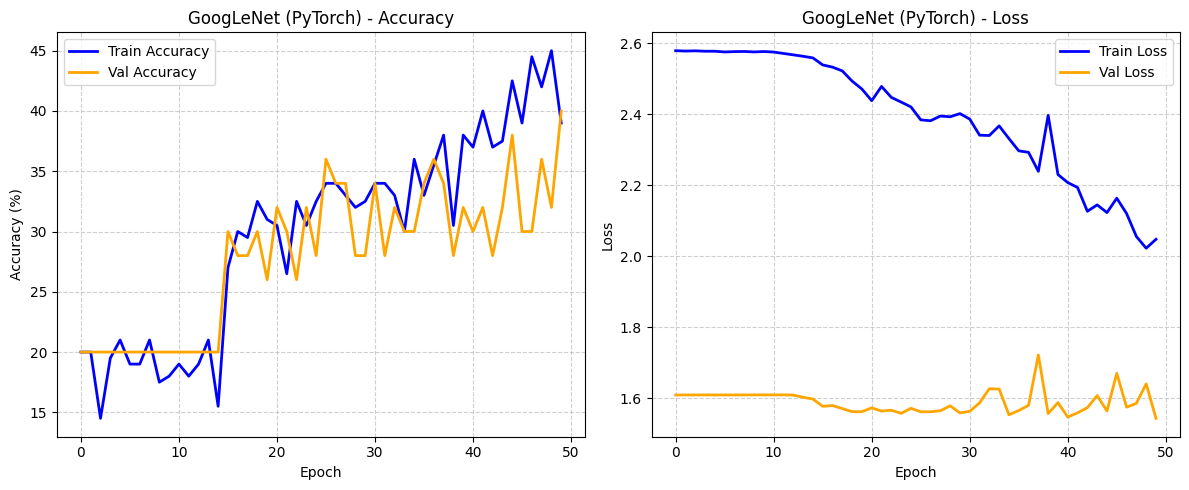

In [ ]:
plt.figure(figsize=(12, 5))

# Biểu đồ Accuracy
plt.subplot(1, 2, 1)
plt.plot(train_accuracies, label='Train Accuracy', color='blue', linewidth=2)
plt.plot(val_accuracies, label='Val Accuracy', color='orange', linewidth=2)
plt.title('GoogLeNet (PyTorch) - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Biểu đồ Loss
plt.subplot(1, 2, 2)
plt.plot(train_losses, label='Train Loss', color='blue', linewidth=2)
plt.plot(val_losses, label='Val Loss', color='orange', linewidth=2)
plt.title('GoogLeNet (PyTorch) - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()